# **10. SHAP Model Explainability**

In [6]:
# Import Libraries

import sys
sys.path.append("..")
from src.utilis import *

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pickle
import joblib
import shap

sns.set_style('darkgrid')


In [7]:
# define file path for processed data
parent_path = Path.cwd().parent
processed_file_path = parent_path.joinpath("models", "processed.pkl")
tuned_model_path = parent_path.joinpath("models", "final_tuned_model.joblib")

# Load the necessary data & model for model explaination
display_md(f"**Loading processed data & tuned model...**")
try:
    with open(processed_file_path, "rb") as f:
        processed_data = pickle.load(f)

    with open(tuned_model_path, 'rb') as model_tuned:
        tuned_model = joblib.load(model_tuned)


    # Extract features and target variable
    X_train = processed_data["X_train"]
    y_train = processed_data["y_train"]
    X_test = processed_data["X_test"]
    numeric_feat = processed_data["numeric_features"]
    ordinal_feat = processed_data["ordinal_features"]
    categorical_feat = processed_data["categorical_features"]
    boolean_feat = processed_data["boolean_features"]
    year_feat = processed_data["year_features"]
    test_id = processed_data['test_id']
    total_numeric_features = ordinal_feat + numeric_feat + year_feat + boolean_feat
    print("Data & Model Loaded Successfully!")
    
except Exception as e:
    print(f"ErrorRaised : {e}")



**Loading processed data & tuned model...**

Data & Model Loaded Successfully!


## **2. Model Interpretability & Documentation**

In [8]:
# Extract and document the model components
print("\n ==== MODEL DOCUMENTATION ====")
selected_numeric_features = []
selected_categorical_features = []
# Check the model type
model_type = tuned_model.named_steps['model'].__class__.__name__
print(f"Fine Tuned Model : {model_type}")

# Get hyperparameter if possible
if hasattr(tuned_model.named_steps['model'], 'alpha'):
    print(f"Alpha (regularlization strength) : {tuned_model.named_steps['model'].alpha:.1f}")
if hasattr(tuned_model.named_steps['model'], 'l1_ratio'):
    print(f"l1 Ratio : {tuned_model.named_steps['model'].l1_ratio}")
if hasattr(tuned_model.named_steps['model'], 'max_iter'):
    print(f"Max Iteration : {tuned_model.named_steps['model'].max_iter}")

# Document the preprocessing steps
print("\nPreprocessing Pipeline :")
for name, transformer, features in tuned_model.named_steps['preprocessor'].transformers_:
    if name == 'numeric':
        selected_numeric_features.extend(features)
        print(f" - Numeric Features ({len(features)}) : {', '.join(features)}")
        for step_name, step in transformer.steps:
            print(f"  * {step_name} : {step.__class__.__name__}")

    elif name == 'cat':
        selected_categorical_features.extend(features)
        print(f"\n - Categorical Features ({len(features)}) : {', '.join(features)}")
        for step_name, step in transformer.steps:
            print(f"  * {step_name} : {step.__class__.__name__}")




 ==== MODEL DOCUMENTATION ====
Fine Tuned Model : Ridge
Alpha (regularlization strength) : 100.0
Max Iteration : 10000

Preprocessing Pipeline :
 - Numeric Features (20) : ExterQual, KitchenQual, BsmtQual, GarageFinish, OverallQual, GarageCars, Fireplaces, TotalBathrooms, TotRmsAbvGrd, TotalSF, NeighborhoodMedianPrice, HouseAge, RemodeledAge, MasVnrArea, TotalPorchSF, BsmtFinSF1, Log_TotalSF, Log_MasVnrArea, GarageYrBlt, CentralAir
  * imputer : SimpleImputer
  * scaler : StandardScaler

 - Categorical Features (1) : Neighborhood
  * imputer : SimpleImputer
  * onehot : OneHotEncoder


## **3. Preparing Data and Model for SHAP**

--- Preparing Data and Model for SHAP ---
Champion Ridge Regression model re-trained successfully.

--- Generating SHAP Explanations ---

1. Global Feature Importance (Summary Plot)


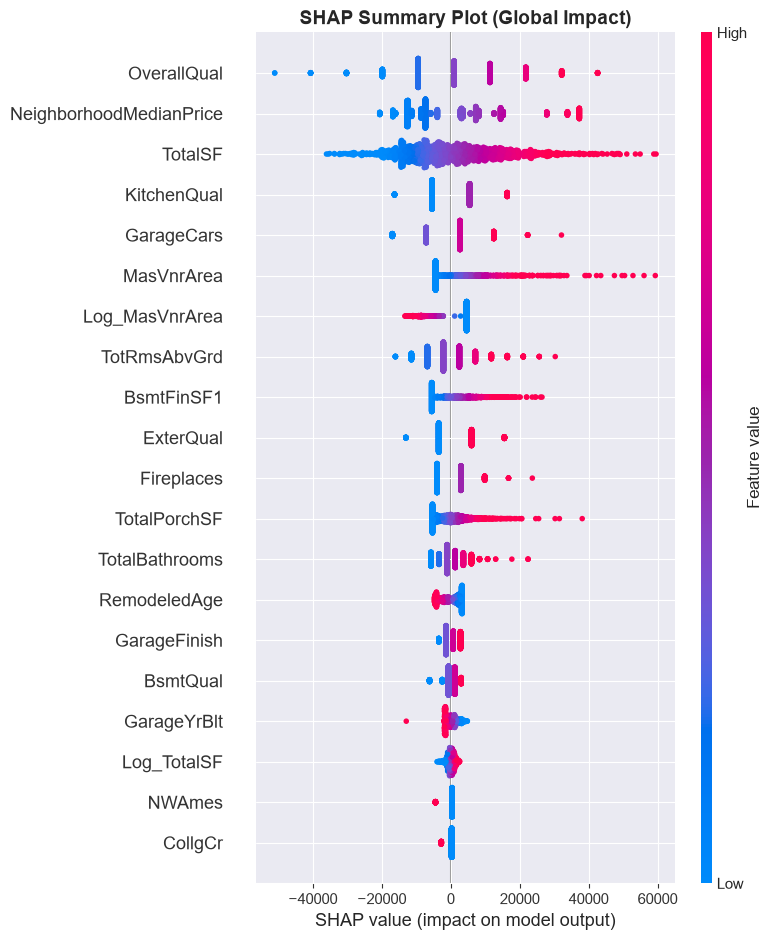


2. Local Explanation: Why did the model predict this specific price?


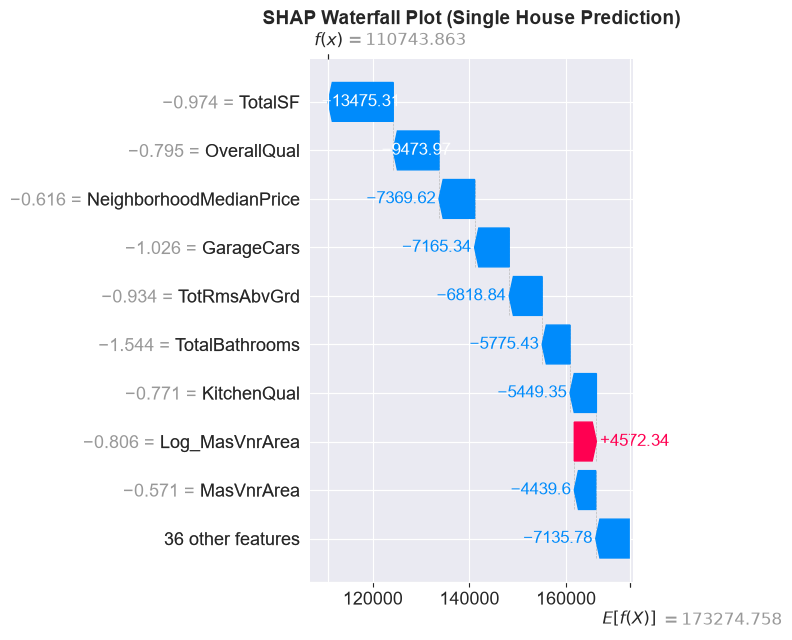


3. Feature Dependence Plot: Overall Quality vs. Price Impact


<Figure size 1000x600 with 0 Axes>

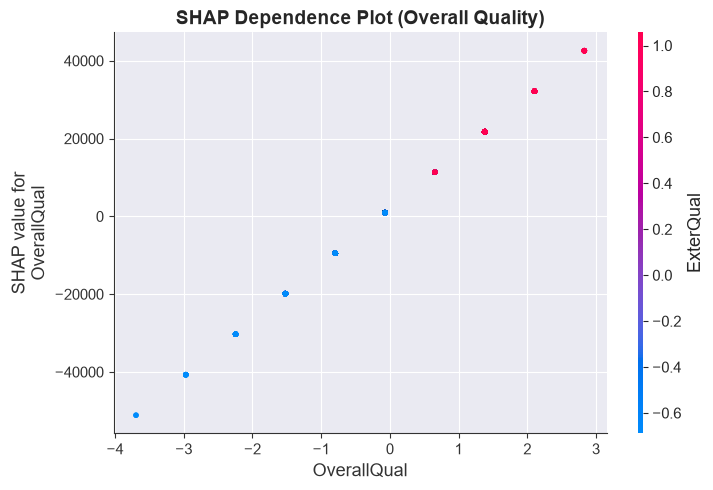

In [10]:
print("--- Preparing Data and Model for SHAP ---")

# 1. Re-train Champion Model with the exact best parameters
tuned_model.fit(X_train, y_train)
print("Champion Ridge Regression model re-trained successfully.")

# --- Model Explainability with SHAP ---
print("\n--- Generating SHAP Explanations ---")

# Step 1: Extract the fitted preprocessor and Ridge model
preprocessor = tuned_model.named_steps["preprocessor"]
ridge_model = tuned_model.named_steps["model"]

# Step 2: Transform X_train and X_test
X_train_transformed = preprocessor.transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

# Step 3: Get the transformed feature names
feature_names = preprocessor.get_feature_names_out()
selected_features = [
    name.replace("numeric__", "").replace("cat__Neighborhood_", "")
    for name in feature_names.tolist()
]

# Step 4: Create the SHAP LinearExplainer
explainer = shap.LinearExplainer(
    ridge_model,
    X_train_transformed,
    max_samples=1459
)

# Step 5: Calculate SHAP values for X_test
shap_value = explainer.shap_values(X_test_transformed)
shap_obj = explainer(X_test_transformed)

# --- Plot 1: SHAP Summary Plot ---
# Step 6: Visualize the results
# summary plot
print("\n1. Global Feature Importance (Summary Plot)")
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_value,
    X_test_transformed,
    feature_names=selected_features,
    show=False
)
plt.title("SHAP Summary Plot (Global Impact)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Plot 2: SHAP Waterfall Plot ---
# Step 7: Waterfall plot: Explain one house prediction
print("\n2. Local Explanation: Why did the model predict this specific price?")
plt.figure(figsize=(10, 6))

shap_values = explainer(X_test_transformed)
shap_exp = shap.Explanation(
    values = shap_values.values[0],
    base_values= shap_values.base_values[0],
    data = X_test_transformed[0].toarray().flatten()
    if hasattr(X_test_transformed[0], "toarray")
    else X_test_transformed[0],
    feature_names=selected_features
)
shap.plots.waterfall(
    shap_exp,
    max_display=10,
    show=False
)
plt.title("SHAP Waterfall Plot (Single House Prediction)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Plot 3: SHAP Dependence Plot ---
# Step 8: Dependence Plot
print("\n3. Feature Dependence Plot: Overall Quality vs. Price Impact")
plt.figure(figsize=(10, 6))
shap.dependence_plot(
    "OverallQual",
    shap_value,
    X_test_transformed,
    feature_names=selected_features,
    show=False
)
plt.title("SHAP Dependence Plot (Overall Quality)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()



## **4. Feature Importance**


--- Feature Importance (Ridge Regression) ---


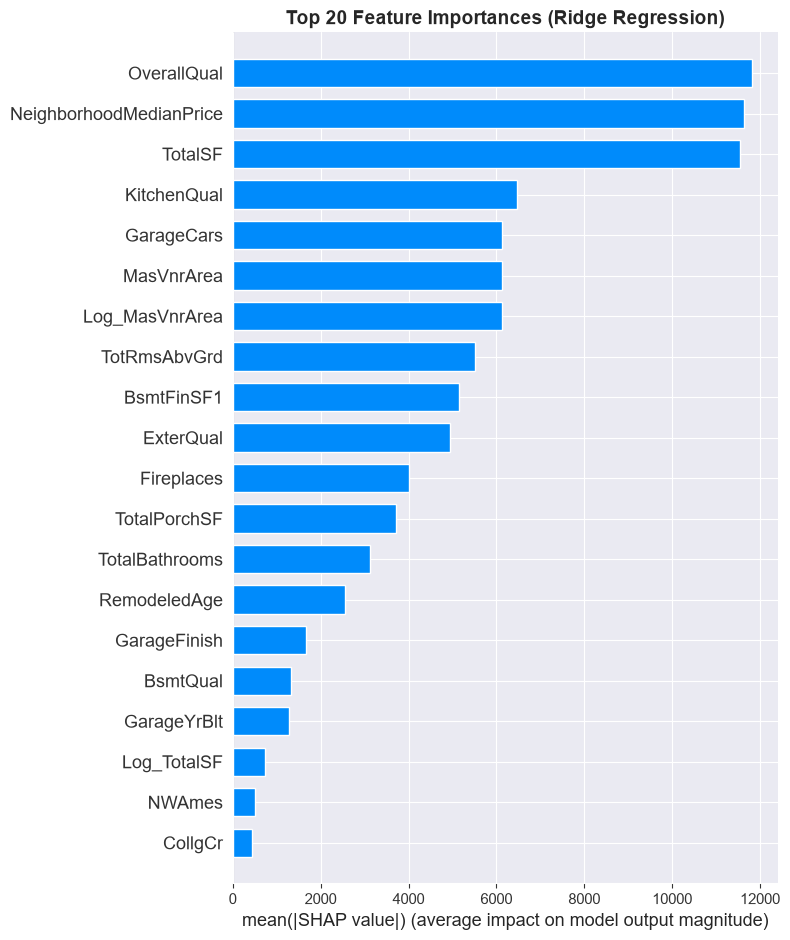

In [11]:
# --- Feature Importance (Ridge Regression) using SHAP ---
print("\n--- Feature Importance (Ridge Regression) ---")
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_value,
    X_test_transformed,
    feature_names=selected_features,
    plot_type="bar",
    show=False
)
plt.title('Top 20 Feature Importances (Ridge Regression)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()



Top 20 most important features:


,Feature,Coefficient,Absolute_Coefficient,Mean_Absolute_SHAP
0,TotalSF,15754.44,15754.44,11536.68
1,OverallQual,14358.99,14358.99,11815.26
2,NeighborhoodMedianPrice,14285.49,14285.49,11637.56
3,MasVnrArea,8892.33,8892.33,6126.94
4,TotRmsAbvGrd,7519.97,7519.97,5516.70
5,GarageCars,7328.45,7328.45,6130.70
6,KitchenQual,7221.64,7221.64,6459.18
7,BsmtFinSF1,6344.38,6344.38,5154.29
8,ExterQual,5456.37,5456.37,4940.11
9,BrkSide,4868.46,4868.46,303.10


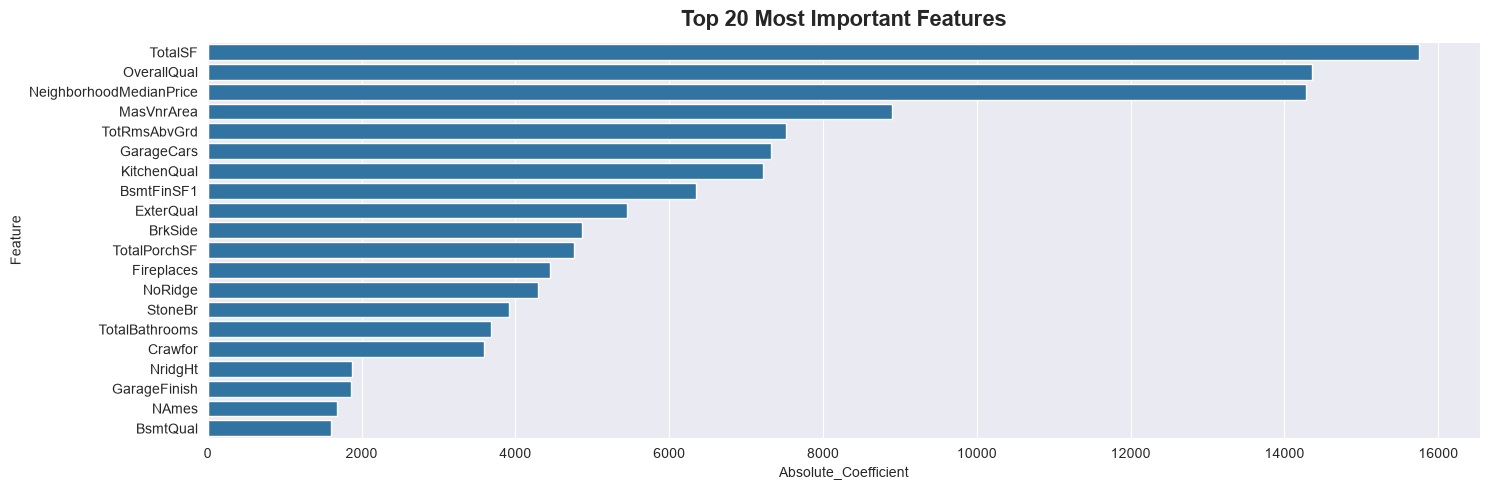

In [39]:
coef = ridge_model.coef_
mean_abs_shap = np.abs(shap_value).mean(axis=0)
feature_importance = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coef,
    "Absolute_Coefficient": np.abs(coef),
    "Mean_Absolute_SHAP": mean_abs_shap
    })
top_features = feature_importance.sort_values('Coefficient', ascending=False,ignore_index=True)
# Display top 20 most important features
print("\nTop 20 most important features:")
display(top_features.head(20))

# Visualize feature importance
plt.figure(figsize=(15, 5))
sns.barplot(x='Absolute_Coefficient', y='Feature', data=top_features.head(20))
plt.title('Top 20 Most Important Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


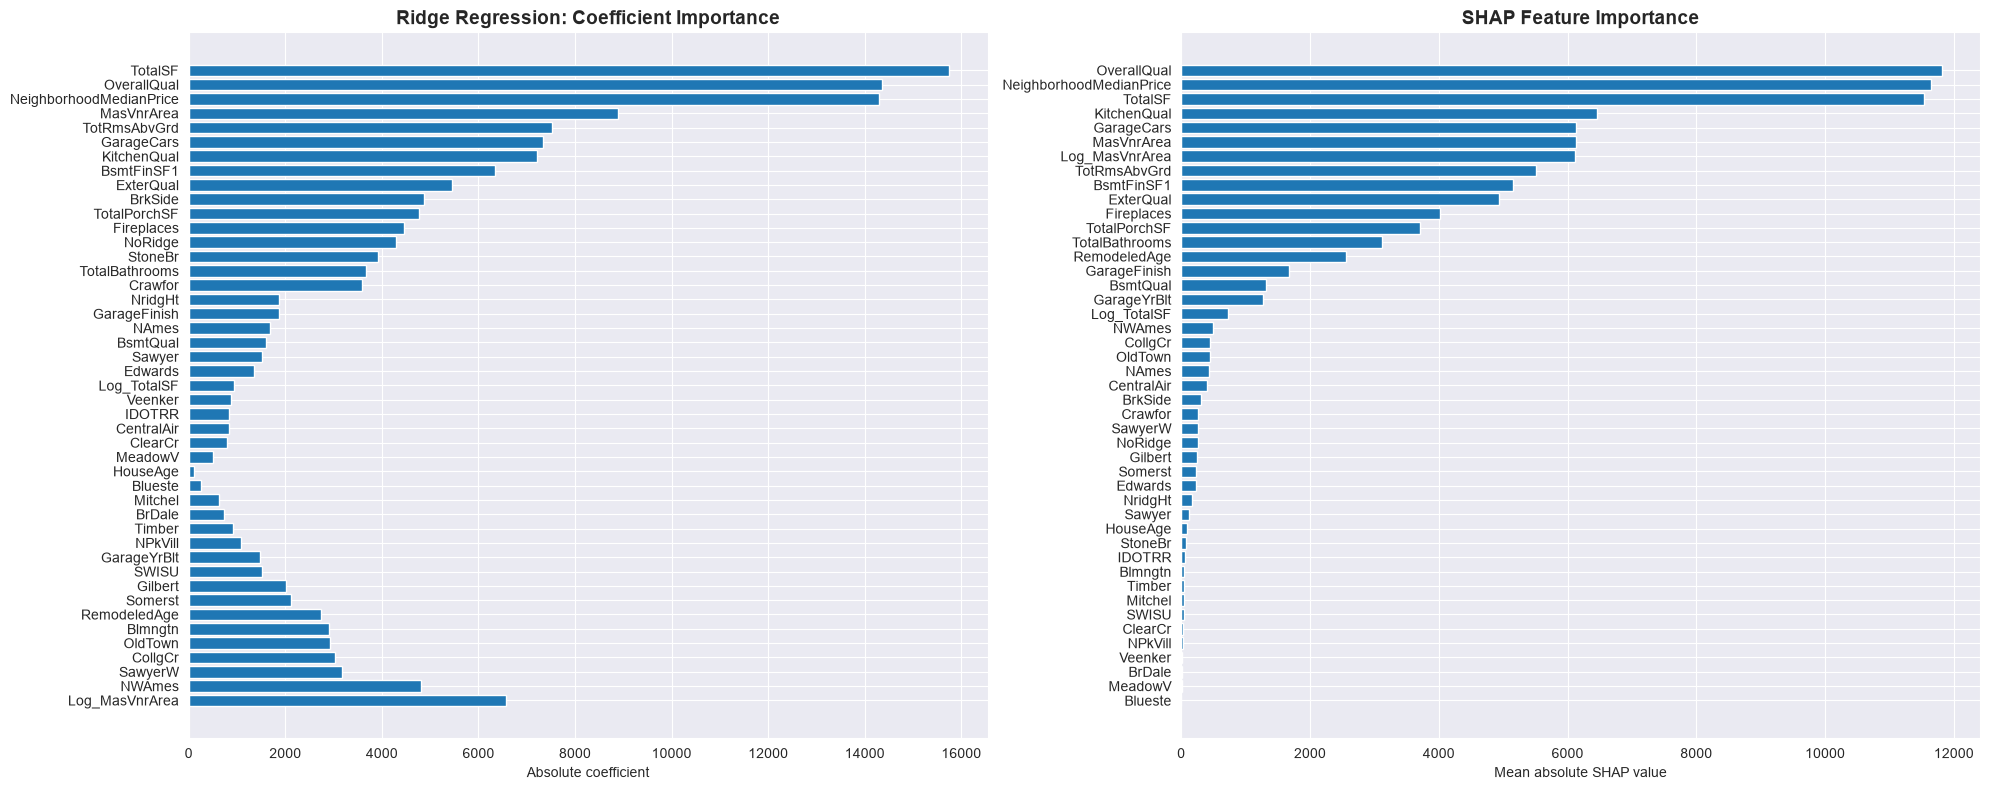

In [67]:
importance_df = feature_importance.sort_values(by='Mean_Absolute_SHAP', ascending=True, ignore_index=True)
top_feature = feature_importance.sort_values('Coefficient', ascending=True,ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(20, 8))

ax[0].barh(
    top_feature["Feature"],
    top_feature['Absolute_Coefficient']
)
ax[0].set_title("Ridge Regression: Coefficient Importance", fontsize=14, fontweight='bold')
ax[0].set_xlabel("Absolute coefficient")

ax[1].barh(
    importance_df["Feature"],
    importance_df["Mean_Absolute_SHAP"]
)
ax[1].set_title("SHAP Feature Importance", fontsize=14, fontweight='bold')
ax[1].set_xlabel("Mean absolute SHAP value")

plt.tight_layout()
plt.subplots_adjust(hspace=0.3)
plt.show()
